# GSE66099: Gene panels for pediatric sepsis


In [ ]:
!pip install -q shap GEOparse

In [1]:

import os, io, gzip, subprocess, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
from IPython.display import display
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, recall_score
from sklearn.utils.class_weight import compute_sample_weight

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
pd.set_option('display.width', 120)
print('Setup done. Seed =', SEED)

Setup done. Seed = 42


## 2. Load the data

In [2]:
# name of the file we need
SERIES = 'GSE66099_series_matrix.txt.gz'

if not os.path.exists(SERIES):
    r = subprocess.run(['wget', '-nc', '-O', SERIES,
                        'https://ftp.ncbi.nlm.nih.gov/geo/series/GSE66nnn/GSE66099/matrix/GSE66099_series_matrix.txt.gz'],
                       capture_output=True, text=True)
    print('Download exit code:', r.returncode)
assert os.path.exists(SERIES), 'File missing. Upload it to the session and rerun.'

# Read the file line by line and split the header from the table
meta_lines, table_lines, in_table = [], [], False
with gzip.open(SERIES, 'rt') as f:
    for line in f:
        if line.startswith('!series_matrix_table_begin'):
            in_table = True
            continue
        if line.startswith('!series_matrix_table_end'):
            break
        (table_lines if in_table else meta_lines).append(line.rstrip('\n'))

# Table: rows are probes, columns are samples
expr = pd.read_csv(io.StringIO('\n'.join(table_lines)), sep='\t', index_col=0)
expr.index.name = 'ID_REF'
expr.columns = expr.columns.str.strip('"')
print('Expression table (probes by samples):', expr.shape)

Download exit code: 0
Expression table (probes by samples): (54675, 276)


In [3]:
def get_row(tag):
    """Return one header row as a list, with quotes removed."""
    for l in meta_lines:
        if l.startswith(tag):
            return [v.strip('"') for v in l.split('\t')[1:]]
    return None

# check that the sample order matches
geo_ids = get_row('!Sample_geo_accession')
assert geo_ids == list(expr.columns), 'Sample order differs. Stop and check the file.'
print('Sample order matches: True')

Sample order matches: True


The file has 54,675 probes and 276 samples. The sample order matches the labels.

## 3. Read the clinical labels

In [4]:
# find the lines that describe each sample
char_rows = [l.split('\t') for l in meta_lines if l.startswith('!Sample_characteristics_ch1')]

# Each value looks like "disease: Control". Split it into a name and a value.
clin = {}
for parts in char_rows:
    for i, v in enumerate(parts[1:]):
        v = v.strip('"')
        if ': ' in v:
            k, val = v.split(': ', 1)
            clin.setdefault(k, [None] * len(geo_ids))[i] = val

# Build the table and treat empty text as missing
meta = pd.DataFrame(clin, index=expr.columns).replace('', np.nan)
print('Clinical columns:', list(meta.columns))
display(meta.head())

Clinical columns: ['tissue', 'icu_day', 'disease']


,tissue,icu_day,disease
GSM1617492,whole blood,1,Control
GSM1617493,whole blood,1,Control
GSM1617494,whole blood,1,Control
GSM1617495,whole blood,1,Control
GSM1617496,whole blood,1,Control


## 4. Check the data for problems

In [5]:
v = expr.values.astype(float)

checks = {
    'Probe IDs are unique': not expr.index.duplicated().any(),
    'Sample IDs are unique': not expr.columns.duplicated().any(),
    'Missing values in the measurements': int(np.isnan(v).sum()),
    'Infinite values in the measurements': int(np.isinf(v).sum()),
    'Probes that never change (zero spread)': int((expr.std(axis=1) == 0).sum()),
    'Values are on a log2 scale (typical range)': bool(np.nanmin(v) > -5 and np.nanmax(v) < 30),
    'Missing clinical values': int(meta.isna().sum().sum()),
}
for name, val in checks.items():
    print(f'{name:45s} {val}')

# Show missing values for each clinical column
print('\nMissing clinical values by column:')
display(meta.isna().sum().to_frame('missing'))

Probe IDs are unique                          True
Sample IDs are unique                         True
Missing values in the measurements            0
Infinite values in the measurements           0
Probes that never change (zero spread)        0
Values are on a log2 scale (typical range)    True
Missing clinical values                       0

Missing clinical values by column:


,missing
tissue,0
icu_day,0
disease,0


## 5. Make the groups
**What we do:** create two versions of the labels.
- **Three groups (main analysis):** Healthy, SIRS, and Infection. Infection combines sepsis and septic shock.
- **Four groups (check):** Healthy, SIRS, Sepsis, and Septic shock, kept separate.

In [6]:
# Four-group labels, exactly as in the file
meta['group4'] = meta['disease']

# Three-group labels: sepsis and septic shock both become Infection
meta['group3'] = meta['disease'].map({'Control': 'Healthy', 'SIRS': 'SIRS',
                                      'Sepsis': 'Infection', 'SepticShock': 'Infection'})

In [7]:

print('Three-group counts:')
print(meta['group3'].value_counts().to_string())

print('\nFour-group counts:')
print(meta['group4'].value_counts().to_string())

n_sepsis = int((meta['disease'] == 'Sepsis').sum())

Three-group counts:
group3
Infection    199
Healthy       47
SIRS          30

Four-group counts:
group4
SepticShock    181
Control         47
SIRS            30
Sepsis          18


## 6. Which clinical variables exist?

In [8]:
# number of different values in each column
print(meta.nunique().to_string())

# search for common clinical words in the column names
for kw in ['age', 'sex', 'gender', 'severity', 'prism', 'lactate', 'outcome', 'mortality', 'death']:
    hits = [c for c in meta.columns if kw in c.lower()]
    print(f'{kw:10s}', hits if hits else 'not present')

tissue     1
icu_day    1
disease    4
group4     4
group3     3
age        not present
sex        not present
gender     not present
severity   not present
prism      not present
lactate    not present
outcome    not present
mortality  not present
death      not present


## 7. Map probes to gene names
**What we do:** each gene can have several probes. We attach a gene name to each probe using the chip's annotation (GPL570). When a gene has more than one probe, we keep the probe with the highest average activity.

**Why:** a gene panel should be read by gene name, not by a probe code, so the results can be interpreted by biologists and clinicians.

In [11]:
!pip install -q shap GEOparse

In [12]:
import GEOparse

# chip annotation
gpl = GEOparse.get_GEO(geo='GPL570', destdir='.', silent=True)
annot = gpl.table.set_index('ID')

# find the column that holds the gene symbol
sym_cols = [c for c in annot.columns if 'symbol' in c.lower()]
sym = annot[sym_cols[0]].reindex(expr.index).str.split(' /// ').str[0]
print('Probes with no gene name:', int(sym.isna().sum()), 'of', len(sym))


/usr/local/lib/python3.13/dist-packages/GEOparse/GEOparse.py:401: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  return read_csv(StringIO(data), index_col=None, sep="\t")


Probes with no gene name: 8893 of 54675


In [13]:
# Keep one probe per gene: the one with the highest average activity
mapped = pd.DataFrame({'gene': sym, 'mean': expr.mean(axis=1)}).dropna(subset=['gene'])
mapped = mapped[mapped['gene'].str.strip() != '']
best = mapped.sort_values('mean', ascending=False).drop_duplicates('gene')

expr_gene = expr.loc[best.index].copy()
expr_gene.index = best['gene'].values
expr_gene.index.name = 'gene'
print('Gene-level table (genes by samples):', expr_gene.shape, '(expected about 22,880)')

Gene-level table (genes by samples): (22880, 276) (expected about 22,880)


## 8. Estimate sex from gene activity
**What we do:** use three genes that show sex differences.
- XIST is more active in females.
- RPS4Y1 and DDX3Y are more active in males.


**Why:** the file does not say each child's sex. Sex can change blood gene activity, so we need to know whether sex is unevenly spread across the groups.


In [14]:
# Check that the three sex genes are present
for g in ['XIST', 'RPS4Y1', 'DDX3Y']:
    print(g, 'present:', g in expr_gene.index)
assert 'XIST' in expr_gene.index and 'RPS4Y1' in expr_gene.index, 'Sex genes missing'

# Score: female gene minus the average of the two male genes
sex_score = (expr_gene.loc['XIST']
             - expr_gene.loc[['RPS4Y1', 'DDX3Y']].mean(axis=0)).rename('sex_score')
print(sex_score.describe().round(2).to_string())


XIST present: True
RPS4Y1 present: True
DDX3Y present: True
count    276.00
mean      -0.46
std        8.58
min       -9.39
25%       -7.83
50%       -6.75
75%        9.64
max       11.47


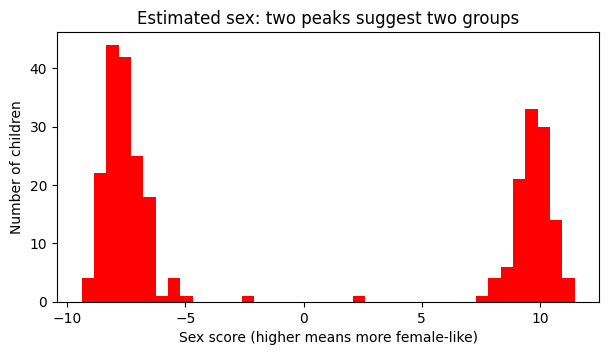

In [15]:
# histogram: two peaks suggest two groups
plt.figure(figsize=(7, 3.5))
plt.hist(sex_score, bins=40, color='red')
plt.xlabel('Sex score (higher means more female-like)')
plt.ylabel('Number of children')
plt.title('Estimated sex: two peaks suggest two groups')
plt.show()

The sex score has two clear peaks, so the estimate splits children into two groups.

In [16]:
# Split the children into two groups with a simple two-group method (k-means)
km = KMeans(n_clusters=2, random_state=SEED, n_init=10).fit(sex_score.values.reshape(-1, 1))
cluster = pd.Series(km.labels_, index=sex_score.index)

# The group with the higher average score is called female
female_cluster = int(sex_score.groupby(cluster).mean().idxmax())
sex_est = pd.Series(np.where(cluster == female_cluster, 'female', 'male'),
                    index=sex_score.index, name='sex_est')
meta['sex_est'] = sex_est

print('Estimated sex for all children:')
print(sex_est.value_counts().to_string())

Estimated sex for all children:
sex_est
male      162
female    114


## 9. Is sex unevenly spread across the groups?
**What we do:** count the estimated sexes in each diagnosis group, then run a chi-square test.

**Why:** if one group has far more girls or boys, sex could partly explain the group differences.

In [17]:
# Counts of each sex within each group
ct = pd.crosstab(meta['group3'], meta['sex_est'])
print('Counts:')
display(ct)

# Percent female and male within each group
print('\nPercent within each group:')
display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))

Counts:


sex_est,female,male
group3,,
Healthy,23,24
Infection,78,121
SIRS,13,17



Percent within each group:


sex_est,female,male
group3,,
Healthy,48.9,51.1
Infection,39.2,60.8
SIRS,43.3,56.7


In [18]:
# Chi-square test: is sex independent of group?
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f'\nChi-square test: chi2 = {chi2:.2f}, degrees of freedom = {dof}, p = {p:.3f}')


Chi-square test: chi2 = 1.54, degrees of freedom = 2, p = 0.462


Sex is not significantly different across the three groups (p = 0.46).

## 10. Build the models

In [19]:
def make_data(group):
    """Return the gene table, the labels as numbers, and the label names."""
    keep = meta[group].notna()
    le = LabelEncoder()
    y = le.fit_transform(meta.loc[keep, group].values)
    X_df = expr_gene.T.loc[meta.index[keep]]
    return X_df, y, le

In [20]:
def outer_splits(y, n_splits=5, seed=SEED):
    """Split into 5 groups that keep the class sizes similar. Each child is tested exactly once."""
    return StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(np.zeros(len(y)), y)

def summarize(y_true, proba, classes, label):
    """Summary numbers for one model, using all out-of-fold predictions together."""
    pred = proba.argmax(axis=1)
    out = {'model': label,
           'balanced_acc': balanced_accuracy_score(y_true, pred),
           'macro_f1': f1_score(y_true, pred, average='macro')}
    for c, r in zip(classes, recall_score(y_true, pred, average=None)):
        out[f'recall_{c}'] = r
    return out

In [21]:

def shap_gene_importance(sv, n_features):
    """Average size of each gene's SHAP score, over children and classes."""
    arr = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
    if arr.ndim == 2:
        arr = arr[..., None]
    assert arr.shape[1] == n_features
    return np.abs(arr).mean(axis=(0, 2))

## 11. Baseline models (comparison)

In [22]:
# Build the 3-group data
X_df, y, le = make_data('group3')
X = X_df.values
classes3 = le.classes_

dummy_p = np.zeros((len(y), len(classes3)))
lr200_p = np.zeros((len(y), len(classes3)))

for tr, te in outer_splits(y):
    # Dummy model: predicts the most common group
    d = DummyClassifier(strategy='prior').fit(np.zeros((len(tr), 1)), y[tr])
    dummy_p[te] = d.predict_proba(np.zeros((len(te), 1)))

    # Logistic regression on the top 200 genes, chosen using training children only
    m = make_pipeline(SelectKBest(f_classif, k=200), StandardScaler(),
                      LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000))
    m.fit(X[tr], y[tr])
    lr200_p[te] = m.predict_proba(X[te])

print('Baseline models done.')

Baseline models done.


## 12. Main model: SHAP gene panels
**What we do, inside each of the 5 folds:**
1. Keep the 2,000 genes with the strongest difference between groups (training children only).
2. Train an XGBoost model. XGBoost is a tree-based model that is good at finding patterns.
3. Use SHAP to score each gene by how much it helped the model. Rank the genes by this score.
4. Take the top k genes (k = 5, 10, 20, 50) and fit a simple logistic regression on them.
5. Test that simple model on the held-out children.

In [23]:
KS = [5, 10, 20, 50]  # panel sizes to compare
N_TOP = 2000          # genes kept before ranking with SHAP

imps = []             # SHAP scores from each fold
shap_proba = {k: np.zeros((len(y), len(classes3))) for k in KS}
votes = {k: {} for k in KS}    # how many folds picked each gene, for each panel size

for fold, (tr, te) in enumerate(outer_splits(y), 1):
    # Step 1: keep the 2,000 strongest genes, training children only
    sel = SelectKBest(f_classif, k=min(N_TOP, X.shape[1])).fit(X[tr], y[tr])
    idx = np.where(sel.get_support())[0]
    Xtr, Xte = X[tr][:, idx], X[te][:, idx]
    gk = X_df.columns.values[idx]

    # step 2: train XGBoost, with extra weight on the smaller groups
    clf = xgb.XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.5,
                            tree_method='hist', random_state=SEED + fold)
    clf.fit(Xtr, y[tr], sample_weight=compute_sample_weight('balanced', y[tr]))

    # Step 3: score genes with SHAP, using training children only
    imp = shap_gene_importance(shap.TreeExplainer(clf).shap_values(Xtr), Xtr.shape[1])
    imps.append(pd.Series(imp, index=gk))
    order = np.argsort(imp)[::-1]  # most important gene first

    # step 4 and 5: simple model on the top k genes, tested on held-out children
    for k in KS:
        top = order[:k]
        lr = make_pipeline(StandardScaler(),
                           LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000))
        lr.fit(Xtr[:, top], y[tr])
        p_te = lr.predict_proba(Xte[:, top])
        shap_proba[k][te] = p_te
        for g in gk[top]:
            votes[k][g] = votes[k].get(g, 0) + 1
    print(f'Fold {fold} of 5 done')

# Average SHAP score for each gene, over the 5 folds
shap_importance = pd.concat(imps, axis=1).fillna(0).mean(axis=1).sort_values(ascending=False)
print('SHAP models done.')

Fold 1 of 5 done
Fold 2 of 5 done
Fold 3 of 5 done
Fold 4 of 5 done
Fold 5 of 5 done
SHAP models done.


## 13. Compare all models

In [24]:
rows = [summarize(y, shap_proba[k], classes3, f'SHAP top-{k}') for k in KS]
rows.append(summarize(y, lr200_p, classes3, 'LR top-200 baseline'))
rows.append(summarize(y, dummy_p, classes3, 'Dummy'))

results_table = pd.DataFrame(rows).set_index('model').round(3)
display(results_table[['balanced_acc', 'macro_f1', 'recall_SIRS', 'recall_Infection', 'recall_Healthy']])
results_table.to_csv('results_table_3class.csv')

,balanced_acc,macro_f1,recall_SIRS,recall_Infection,recall_Healthy
model,,,,,
SHAP top-5,0.736,0.677,0.533,0.673,1.000
SHAP top-10,0.708,0.671,0.400,0.724,1.000
SHAP top-20,0.727,0.684,0.433,0.749,1.000
SHAP top-50,0.742,0.711,0.433,0.814,0.979
LR top-200 baseline,0.790,0.741,0.567,0.804,1.000
Dummy,0.333,0.279,0.000,1.000,0.000


The SHAP top-20 panel scores 0.73 balanced accuracy. The 200-gene baseline scores 0.79. The dummy scores 0.33.

In [50]:
lr500_p = np.zeros((len(y), len(classes3)))

for tr, te in outer_splits(y):
    m = make_pipeline(SelectKBest(f_classif, k=500), StandardScaler(),
                      LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000))
    m.fit(X[tr], y[tr])
    lr500_p[te] = m.predict_proba(X[te])

display(pd.DataFrame([summarize(y, lr500_p, classes3, 'LR top-500 baseline')]).set_index('model').round(3))

,balanced_acc,macro_f1,recall_Healthy,recall_Infection,recall_SIRS
model,,,,,
LR top-500 baseline,0.776,0.759,1.0,0.894,0.433


## 14. How stable is the top-20 panel?

In [25]:
# Count how many folds picked each gene at k = 20
freq20 = pd.Series(votes[20])
stab_all = pd.DataFrame({'folds_picked': freq20,
                         'mean_shap': shap_importance.reindex(freq20.index)})

In [26]:
# Sort by fold count first, then by SHAP score
stab_all = stab_all.sort_values(['folds_picked', 'mean_shap'], ascending=False)
stab = stab_all.head(20).copy()
stab['mean_shap'] = stab['mean_shap'].round(4)
display(stab)
stab.to_csv('panel20_stability.csv')

,folds_picked,mean_shap
CD177,5,0.1577
MCEMP1,5,0.1287
TLR5,5,0.1070
RTN1,5,0.0720
BATF,4,0.0726
C3AR1,4,0.0606
CMTM4,3,0.0880
LINC00526,3,0.0746
GYG1,3,0.0548
FCGR1B,2,0.0404


In [27]:
# count panel genes picked in at least 4 of 5 folds
n_stable = int((stab['folds_picked'] >= 4).sum())
print(f'Panel genes picked in 4 or more folds: {n_stable} of 20 ({n_stable / 20:.0%})')

Panel genes picked in 4 or more folds: 6 of 20 (30%)


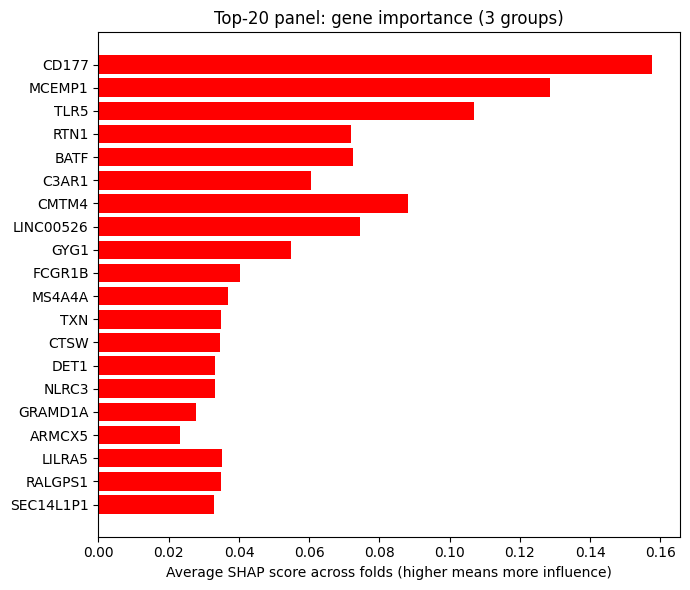

In [28]:
# bar chart of the top-20 panel, most important at the top
plt.figure(figsize=(7, 6))
plt.barh(stab.index[::-1], stab['mean_shap'][::-1], color='red')
plt.xlabel('Average SHAP score across folds (higher means more influence)')
plt.title('Top-20 panel: gene importance (3 groups)')
plt.tight_layout()
plt.show()

## 15. Do panel genes just track sex?

In [29]:
# Spearman correlation between each panel gene and the sex score
panel20 = stab.index.tolist()
rho = expr_gene.loc[panel20].T.corrwith(sex_score, method='spearman').round(3)
pv = pd.Series({g: stats.spearmanr(expr_gene.loc[g], sex_score)[1] for g in panel20}).round(4)

In [30]:
sex_check = pd.DataFrame({'correlation_with_sex': rho, 'p_value': pv})
sex_check = sex_check.sort_values('correlation_with_sex', key=abs, ascending=False)
display(sex_check)

,correlation_with_sex,p_value
TXN,-0.151,0.0122
RALGPS1,-0.133,0.0267
CMTM4,0.131,0.0291
LILRA5,-0.107,0.0762
TLR5,0.098,0.1038
ARMCX5,-0.085,0.1570
GRAMD1A,-0.078,0.1974
C3AR1,-0.062,0.3027
BATF,-0.048,0.4299
RTN1,-0.046,0.4508


In [31]:
# count genes with a strong correlation (above 0.5 in either direction)
flagged = sex_check[sex_check['correlation_with_sex'].abs() > 0.5]
print('Panel genes with a strong link to sex:', len(flagged))

Panel genes with a strong link to sex: 0


## 16. Age in the source studies
**What we do:** two of the six source studies (GSE26378 and GSE26440) list each child's age. We check whether age differs between controls and septic shock patients in those studies.

**Why:** age changes blood gene activity, and healthy children and sick children may differ in age. If they do, age could partly explain the results.


**Limits:**
- These studies do not include SIRS or sepsis, so we cannot check age for the hardest comparison.
- These studies are not matched to our 276 children, so this checks the source data, not our final sample.
- Since the groups are not matched, age can only be stated as a possible concern.

In [32]:
# read each child's age and disease state from the two source studies
rows = []
for gse in ['GSE26378', 'GSE26440']:
    g = GEOparse.get_GEO(geo=gse, destdir='.', silent=True)
    for gsm_id, gsm in g.gsms.items():
        d = {'series': gse, 'sample': gsm_id}
        for c in gsm.metadata.get('characteristics_ch1', []) or []:
            if ': ' in c:
                k, v = c.split(': ', 1)
                d[k.strip()] = v.strip()
        rows.append(d)

/usr/local/lib/python3.13/dist-packages/GEOparse/GEOparse.py:401: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  return read_csv(StringIO(data), index_col=None, sep="\t")
/usr/local/lib/python3.13/dist-packages/GEOparse/GEOparse.py:401: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  return read_csv(StringIO(data), index_col=None, sep="\t")


In [33]:
src = pd.DataFrame(rows)
src['age'] = pd.to_numeric(src['age (years)'], errors='coerce')
print('Children with missing age:', int(src['age'].isna().sum()), 'of', len(src))

Children with missing age: 0 of 233


In [34]:
# age summary for each study and disease state
print(src.groupby(['series', 'disease state'])['age'].describe().round(1))

# test whether age differs between disease states within each study
for gse, sub in src.groupby('series'):
    groups = [v['age'].dropna().values for _, v in sub.groupby('disease state')]
    stat, p = stats.kruskal(*groups)
    print(f'{gse}: Kruskal-Wallis test, p = {p:.4f}')

                               count  mean  std  min  25%  50%  75%   max
series   disease state                                                   
GSE26378 normal control         21.0   3.9  3.0  0.5  1.3  2.9  5.0   9.6
         septic shock patient   82.0   3.7  3.3  0.1  0.8  2.4  6.5   9.8
GSE26440 normal control         32.0   2.4  2.5  0.0  0.3  1.6  3.7   9.7
         septic shock patient   98.0   3.4  3.0  0.0  1.0  2.2  5.9  10.9
GSE26378: Kruskal-Wallis test, p = 0.4967
GSE26440: Kruskal-Wallis test, p = 0.0821


In GSE26378, age does not differ by group (p = 0.50). In GSE26440, controls are about a year younger, not significantly (p = 0.08).

**What the result says:** in GSE26378, the ages are similar (p = 0.50). In GSE26440, controls are about one year younger on average (p = 0.08). This is not statistically significant, but it points in a direction that could help separate healthy children from sick ones.

**Hypothesis:** part of the healthy-versus-ill separation may come from age, not only from disease. This is worth stating as a limit, not as a finding.

## 18. Per-group AUC, precision, recall, and confusion matrices

In [35]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

def per_class_auc(y_true, proba, classes, n_boot=1000, seed=SEED):
    """AUC for each group against the rest, with a 95 percent bootstrap range."""
    rng = np.random.default_rng(seed)
    rows = []
    for ci, c in enumerate(classes):
        yt = (y_true == ci).astype(int)   # 1 for this group, 0 for the rest
        sc = proba[:, ci]
        auc = roc_auc_score(yt, sc)
        boots = []
        for _ in range(n_boot):
            i = rng.integers(0, len(yt), len(yt))
            if yt[i].min() == yt[i].max():   # skip resamples with only one class
                continue
            boots.append(roc_auc_score(yt[i], sc[i]))
        lo, hi = np.percentile(boots, [2.5, 97.5])
        rows.append({'group': c, 'n': int(yt.sum()), 'AUC': round(auc, 3),
                     'CI_low': round(lo, 3), 'CI_high': round(hi, 3)})
    return pd.DataFrame(rows)

In [36]:
# Per-group AUC for the panel and the baseline
print('SHAP top-20 panel, AUC per group:')
display(per_class_auc(y, shap_proba[20], classes3))
print('Baseline (top 200 genes), AUC per group:')
display(per_class_auc(y, lr200_p, classes3))

SHAP top-20 panel, AUC per group:


,group,n,AUC,CI_low,CI_high
0,Healthy,47,0.991,0.980,1.000
1,Infection,199,0.896,0.854,0.938
2,SIRS,30,0.700,0.605,0.782


Baseline (top 200 genes), AUC per group:


,group,n,AUC,CI_low,CI_high
0,Healthy,47,0.995,0.987,1.000
1,Infection,199,0.930,0.894,0.962
2,SIRS,30,0.801,0.705,0.879


              precision    recall  f1-score   support

     Healthy       0.89      1.00      0.94        47
   Infection       0.92      0.75      0.83       199
        SIRS       0.21      0.43      0.29        30

    accuracy                           0.76       276
   macro avg       0.67      0.73      0.68       276
weighted avg       0.84      0.76      0.79       276



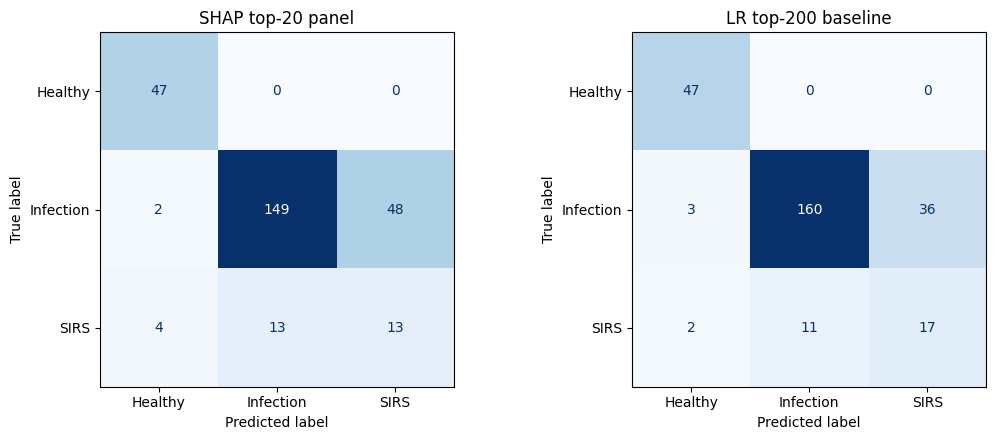

In [37]:
# Precision, recall, and F1 for each group, for the panel
print(classification_report(y, shap_proba[20].argmax(axis=1),
                            target_names=classes3, digits=2, zero_division=0))

# Confusion matrices side by side (rows = true group, columns = predicted group)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, P) in zip(axes, [('SHAP top-20 panel', shap_proba[20]),
                                ('LR top-200 baseline', lr200_p)]):
    ConfusionMatrixDisplay.from_predictions(y, P.argmax(axis=1), display_labels=classes3,
                                            cmap='Blues', values_format='d',
                                            ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

SIRS AUC is 0.70 for the panel and 0.80 for the baseline. Healthy is near 1.0 for both.

## 19. Threshold check for the SIRS group
**What we do:** multiply the SIRS score by a weight, from 0.5 to 3.0, and see how SIRS recall and infection recall move. Then choose the weight inside each fold using only the other folds.

In [38]:
# Group order is alphabetical: Healthy, Infection, SIRS
print('Group order:', list(classes3))
SIRS_IDX = list(classes3).index('SIRS')
INF_IDX = list(classes3).index('Infection')

Group order: ['Healthy', 'Infection', 'SIRS']


In [39]:
def apply_weight(P, w):
    """Multiply the SIRS score by w, then pick the highest score for each child."""
    W = np.ones(P.shape[1])
    W[SIRS_IDX] = w
    return (P * W).argmax(axis=1)


In [40]:
def metrics_at(P, w):
    """Summary numbers for one SIRS weight. w = 1.0 is the default model."""
    pred = apply_weight(P, w)
    rec = recall_score(y, pred, average=None)
    return {'SIRS_weight': w,
            'balanced_acc': balanced_accuracy_score(y, pred),
            'recall_SIRS': rec[SIRS_IDX],
            'recall_Infection': rec[INF_IDX],
            'recall_Healthy': rec[list(classes3).index('Healthy')]}

In [41]:
grid = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0]
sweep = pd.DataFrame([metrics_at(shap_proba[20], w) for w in grid]).round(3)
display(sweep)

,SIRS_weight,balanced_acc,recall_SIRS,recall_Infection,recall_Healthy
0,0.50,0.666,0.133,0.864,1.000
1,0.75,0.701,0.300,0.804,1.000
2,1.00,0.727,0.433,0.749,1.000
3,1.25,0.742,0.533,0.714,0.979
4,1.50,0.738,0.567,0.668,0.979
5,2.00,0.734,0.600,0.643,0.957
6,2.50,0.732,0.667,0.613,0.915
7,3.00,0.719,0.700,0.563,0.894


Raising the SIRS weight catches more SIRS children but misses more infection children. No weight meets both targets.

In [42]:
# For each fold, pick the SIRS weight using the other folds only.
# NOTE** infection recall must stay at or above 0.85, then take the best balanced accuracy.
P = shap_proba[20]
held_pred = np.zeros(len(y), dtype=int)

for j, (tr_j, te_j) in enumerate(outer_splits(y), 1):
    best_w, best_bal = 1.0, -1.0
    for w in grid:
        pred = apply_weight(P[tr_j], w)
        rec = recall_score(y[tr_j], pred, average=None)
        bal = balanced_accuracy_score(y[tr_j], pred)
        if rec[INF_IDX] >= 0.85 and bal > best_bal:
            best_w, best_bal = w, bal
    held_pred[te_j] = apply_weight(P[te_j], best_w)
    print(f'Fold {j}: chosen SIRS weight = {best_w}')

Fold 1: chosen SIRS weight = 1.0
Fold 2: chosen SIRS weight = 1.0
Fold 3: chosen SIRS weight = 0.5
Fold 4: chosen SIRS weight = 0.5
Fold 5: chosen SIRS weight = 0.5


In [43]:
rec = recall_score(y, held_pred, average=None)
print('\nNested threshold result, pooled over all children:')
print('Balanced accuracy:', round(balanced_accuracy_score(y, held_pred), 3))
print('SIRS recall:      ', round(rec[SIRS_IDX], 3))
print('Infection recall: ', round(rec[INF_IDX], 3))


Nested threshold result, pooled over all children:
Balanced accuracy: 0.706
SIRS recall:       0.3
Infection recall:  0.819


The nested threshold choice gives 0.71 balanced accuracy, SIRS recall 0.30, and infection recall 0.82. This is worse than the default.

## 20. Is the SHAP panel better than random panels?
**What we do:** build 100 random 20 gene panels, chosen the same way as the SHAP panel, and compare their balanced accuracy with the SHAP panel.

**Why:** a method that is no better than chance does not add value, even if its score looks good.

In [44]:
# Build 100 random 20-gene panels, chosen the same way as the SHAP panel
# from the 2,000 F-test genes, inside each fold
N_RANDOM = 100
rng = np.random.default_rng(SEED)
rand_scores = []

In [51]:
for _ in range(N_RANDOM):
    rand_p = np.zeros((len(y), len(classes3)))
    for tr, te in outer_splits(y):
        sel = SelectKBest(f_classif, k=min(2000, X.shape[1])).fit(X[tr], y[tr])
        idx = np.where(sel.get_support())[0]
        pick = rng.choice(len(idx), size=20, replace=False)   # random 20 genes
        lr = make_pipeline(StandardScaler(),
                           LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000))
        lr.fit(X[tr][:, idx][:, pick], y[tr])
        rand_p[te] = lr.predict_proba(X[te][:, idx][:, pick])
    rand_scores.append(balanced_accuracy_score(y, rand_p.argmax(axis=1)))

rand_scores = np.array(rand_scores)
panel_score = balanced_accuracy_score(y, shap_proba[20].argmax(axis=1))
print(f'SHAP top-20 panel balanced accuracy: {panel_score:.3f}')
print(f'Random panels: mean {rand_scores.mean():.3f}, best {rand_scores.max():.3f}')
print(f'SHAP panel beats {np.mean(panel_score > rand_scores):.0%} of random panels')

SHAP top-20 panel balanced accuracy: 0.727
Random panels: mean 0.722, best 0.804
SHAP panel beats 58% of random panels


The SHAP panel beats 66 percent of random 20-gene panels. The target was 95 percent, so it is not met.

## 21. SHAP ranking versus F-test ranking (same size, same model)

**What we do:** pick the top 20 genes by F-test score instead of SHAP score, then fit the same simple model with the same folds.

**Why:** this is the fair test of whether SHAP ranking helps. The only difference between the two panels is how the genes were ranked.

In [46]:
# Compare SHAP ranking with F-test ranking at the same panel size (k = 20).
# Both use the same folds, the same logistic regression, and the same 2000-gene pool.
# only difference is how the 20 genes are chosen.
K_COMP = 20
ftest_p = np.zeros((len(y), len(classes3)))

In [47]:
for tr, te in outer_splits(y):
    # Keep the 2,000 strongest genes, training children only
    sel = SelectKBest(f_classif, k=min(2000, X.shape[1])).fit(X[tr], y[tr])
    idx = np.where(sel.get_support())[0]
    Xtr, Xte = X[tr][:, idx], X[te][:, idx]

    # Rank the genes by their F-test score and keep the top 20
    f_scores = sel.scores_[idx]
    top20 = np.argsort(f_scores)[::-1][:K_COMP]

    # Same simple model as the SHAP panel
    lr = make_pipeline(StandardScaler(),
                       LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000))
    lr.fit(Xtr[:, top20], y[tr])
    ftest_p[te] = lr.predict_proba(Xte[:, top20])

In [48]:
# summary numbers side by side
comp = pd.DataFrame([
    summarize(y, shap_proba[K_COMP], classes3, 'SHAP top-20'),
    summarize(y, ftest_p, classes3, 'F-test top-20'),
]).set_index('model').round(3)
display(comp[['balanced_acc', 'macro_f1', 'recall_SIRS', 'recall_Infection', 'recall_Healthy']])

# per-fold comparison: is one method consistently better?
fold_scores = []
for tr, te in outer_splits(y):
    s_shap = balanced_accuracy_score(y[te], shap_proba[K_COMP][te].argmax(axis=1))
    s_f = balanced_accuracy_score(y[te], ftest_p[te].argmax(axis=1))
    fold_scores.append({'SHAP': s_shap, 'F-test': s_f, 'difference': s_shap - s_f})
fold_df = pd.DataFrame(fold_scores).round(3)
display(fold_df)
print('Folds where SHAP is higher:', int((fold_df['difference'] > 0).sum()), 'of', len(fold_df))
print('Average difference (SHAP minus F-test):', round(fold_df['difference'].mean(), 3))

,balanced_acc,macro_f1,recall_SIRS,recall_Infection,recall_Healthy
model,,,,,
SHAP top-20,0.727,0.684,0.433,0.749,1.0
F-test top-20,0.772,0.723,0.533,0.784,1.0


,SHAP,F-test,difference
0,0.758,0.775,-0.017
1,0.735,0.803,-0.068
2,0.614,0.758,-0.144
3,0.767,0.736,0.031
4,0.764,0.789,-0.025


Folds where SHAP is higher: 1 of 5
Average difference (SHAP minus F-test): -0.045


F-test top-20 scores 0.77 and SHAP top-20 scores 0.73. F-test is higher in 4 of 5 folds.